## Updates in Week 2:
- Getting Bert and Albert embeddings in Batches.
- Loading the pretrained models on calling the get_embeddings function. With the option to save or delete the pretrained model afterwards. 
  
    Note: Deleting the models after generating the embeddings proved to reduce the amound of consumed memory.

- Comparison of the loading time of different bert and albert models: [Link](https://colab.research.google.com/drive/15wzDZ6SRZwpGmSmMuC4xHUKcn_SOwF3k#scrollTo=Zuhg_vCWtsDj&line=1&uniqifier=1) 
    
    Note: All Bert and Albert models take longer time to return the embeddings than other models. Comparison With the Rest of the models: [Link](https://colab.research.google.com/drive/1DXSCYS35HRquUDhN7yvEbCvkble1oOJc#scrollTo=yYRdIR9bjAob&line=1&uniqifier=1)

- Investigating the bad performance of Bert and Albert embeddings shown in the heat maps of the previous week's notebook:

    Checking the values of the bert embeddings, turned out they have very high magnitudes, so an option for normalizing the embeddings within the range (0,1) was added. [Link](https://colab.research.google.com/drive/1DXSCYS35HRquUDhN7yvEbCvkble1oOJc#scrollTo=tkLqdAL9biqi) 

    Doubting that the problem could be in the tokenizer, a comparison was made with Bert model from HuggingFace, the results were as bad: [Link](https://colab.research.google.com/drive/1fsfRLuVCa6oM02Q4CXi5mKxWHXU_iQDh#scrollTo=X0UoqUvheB0I&line=1&uniqifier=1) 
    
    However, when the average of the sequence embeddings was used instead of the pooled embeddings, both this model [Link](https://colab.research.google.com/drive/15wzDZ6SRZwpGmSmMuC4xHUKcn_SOwF3k#scrollTo=wvQm31I9kauD&line=1&uniqifier=1)  and HuggingFace's model [Link](https://colab.research.google.com/drive/1fsfRLuVCa6oM02Q4CXi5mKxWHXU_iQDh#scrollTo=vhVUE8qNeJLz&line=1&uniqifier=1) showed better results. Note: The time taken to set up a function for  BERT embeddings from HuggingFace is extremely negligible compared to the all setup required for TFHUB.

- Creating the Similarity Calculator class. With similarity functions added from scipy.spatial.distance, namely: [cosine_similarity, minkowski, correlation, jensen_shannon, cityblock_distance, squared_euclidian_distance, euclidean_distance, chebyshev_distance, canberra_distance, braycurtis_distance].

 While the cosine similarity performs well for all models, the choice for Bert and Albert models is a bit unclear. A comparison was made for different Bert and Albert models and different similarity functions: [Link](https://colab.research.google.com/drive/15wzDZ6SRZwpGmSmMuC4xHUKcn_SOwF3k#scrollTo=ALntmTCOcbjk&line=1&uniqifier=1)

- Adding the function get_embeddings_for_csv in the EmbeddingsGenerator class, which takes as an input a csv file path, reads it in batches using pandas, generates the embeddings for a batch, and writes it to an HD5 file. 

    A simple corpus was compiled from the lablled text similarity corpus found [here](https://github.com/PrincetonML/SIF/blob/master/data/sicktest). Which could be used in choosing the right similarity metric for the right model. To run get_embeddings_for_csv, you will have to upload the csv file to Files panel to the left of the colab screen, and you will have to give colab permissions to write to your drive.

## Install Required Libraries

In [0]:
%%capture
# Install the latest Tensorflow version.
!pip3 install --upgrade tensorflow-gpu
# Install TF-Hub.
!pip3 install tensorflow==2.0
!pip3 install tensorflow-hub
!pip3 install bert-for-tf2
!pip3 install sentencepiece

## Import Required Libraries to Python

In [2]:
%matplotlib inline
import tensorflow_hub as hub
import tensorflow as tf 
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sentencepiece as spm
import tokenization
import time
import bert
import h5py
FullTokenizer = bert.bert_tokenization.FullTokenizer

from tensorflow.keras.models import Model
from sklearn.preprocessing import scale,minmax_scale

from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial import distance
from numpy import linalg as LA

/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


## Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Helper Classes: BERT Model


In [0]:
""" 
Adapted and Modifided From https://colab.research.google.com/drive/1hMLd5-r82FrnFnBub-B-fVW78Px4KPX1#scrollTo=gmR3jHYE_y3X
A wrapper class around the main functionality of BERT
The primary method is get_embeddings
"""

class BertModel:

  '''
  Set Up Requried Objects For BERT
  '''
  def __init__(self,
               max_seq_length = 128,
               URL='https://tfhub.dev/tensorflow/bert_en_cased_L-24_H-1024_A-16/2',
               trainable = False,
               delete_models = True):
    
    self.max_seq_length = max_seq_length
    self.url = URL
    self.trainable = trainable
    self.delete_models = delete_models
    self.__is_init = False

  '''
  Takes a list of sentences and returns their embeddings.
  Returns the average of the sequence embeddings
  '''
  def __call__(self, sentences):
    self.init_model() if not self.__is_init else print('Already Initialized')

    input_words_ids, input_masks, segment_ids = self.__tokenize_sentences(sentences)
    __ , sequence_output = self.model([input_words_ids, input_masks, segment_ids])

    if self.delete_models:
      del self.model

    return tf.math.reduce_mean(sequence_output, axis = 1)


  def init_model(self):
    print('Initializing')
    input_word_ids = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                          name="input_word_ids")
    input_mask = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                      name="input_mask")
    segment_ids = tf.keras.layers.Input(shape=(self.max_seq_length,), dtype=tf.int32,
                                        name="segment_ids")
        
    self.model = hub.KerasLayer(self.url, trainable=self.trainable)
    
    pooled_output, sequence_output = self.model([input_word_ids, input_mask, segment_ids])

    self.tokenizer = self.get_tokenizer()

    self.__is_init = True

  def get_tokenizer(self):
    vocab_file = self.model.resolved_object.vocab_file.asset_path.numpy()
    do_lower_case = self.model.resolved_object.do_lower_case.numpy()
    return FullTokenizer(vocab_file, do_lower_case)

  def __tokenize_sentences(self, sentences):
    input_words_ids = []
    input_masks = []
    segments_ids = []

    for sentence in sentences:
      input_word_ids, input_mask, segment_ids = self.__tokenize_sentence(sentence)
      input_words_ids.append(input_word_ids)
      input_masks.append(input_mask)
      segments_ids.append(segment_ids)
    
    return input_words_ids, input_masks, segments_ids


  def __tokenize_sentence(self, sentence):
    stokens = self.tokenizer.tokenize(sentence)
    stokens = ["[CLS]"] + stokens + ["[SEP]"]

    input_ids = self.__get_ids(stokens)
    input_masks = self.__get_masks(stokens)
    input_segments = self.__get_segments(stokens)

    return input_ids, input_masks, input_segments

  def __get_masks(self, tokens):
    """Mask for padding"""
    if len(tokens)> self.max_seq_length:
        raise IndexError("Token length more than max seq length!")
    return [1]*len(tokens) + [0] * (self.max_seq_length - len(tokens))


  def __get_segments(self, tokens):
      """Segments: 0 for the first sequence, 1 for the second"""
      if len(tokens)> self.max_seq_length:
          raise IndexError("Token length more than max seq length!")
      segments = []
      current_segment_id = 0
      for token in tokens:
          segments.append(current_segment_id)
          if token == "[SEP]":
              current_segment_id = 1
      return segments + [0] * (self.max_seq_length - len(tokens))


  def __get_ids(self, tokens):
      """Token ids from Tokenizer vocab"""
      token_ids = self.tokenizer.convert_tokens_to_ids(tokens)
      input_ids = token_ids + [0] * (self.max_seq_length-len(token_ids))
      return input_ids

## Helper Classes: Albert Model

In [0]:
"""
A wrapper class around Albert
"""
class AlbertModel(BertModel):
  def __init__(self, max_seq_length = 128, URL= 'https://tfhub.dev/tensorflow/albert_en_base/1', trainable = False, delete_models = True):
    super(AlbertModel, self).__init__(max_seq_length, URL, trainable, delete_models)

  def get_tokenizer(self):
    sp_model_file = self.model.resolved_object.sp_model_file.asset_path.numpy()
    return tokenization.FullSentencePieceTokenizer(sp_model_file)

## Helper Classes: Embeddings Generator

In [0]:
class EmbeddingsGenerator:
  def __init__(self, elmo_url = 'https://tfhub.dev/google/elmo/3',
               use_url = 'https://tfhub.dev/google/universal-sentence-encoder/4',
               word2vec_url = 'https://tfhub.dev/google/Wiki-words-500/2',
               nnlm_url = 'https://tfhub.dev/google/nnlm-en-dim128/2',
               bert_url = 'https://tfhub.dev/tensorflow/bert_en_cased_L-12_H-768_A-12/2',
               albert_url = 'https://tfhub.dev/tensorflow/albert_en_xxlarge/1',
               delete_models = True):
    
    self.elmo_url = elmo_url
    self.use_url = use_url
    self.word2vec_url = word2vec_url
    self.nnlm_url = nnlm_url
    self.bert_url = bert_url
    self.albert_url = albert_url

    self.delete_models = delete_models

    self.supported_model_names = ['elmo', 'use', 'word2vec', 'nnlm', 'bert', 'albert']


  ## Load a model first, then load all chunks and convert? repeat for all models?
  ## Or load and convert chunk by chunk with every model.
  def get_embeddings_for_csv(self, file, output_dir, chunk_size = 20, model_names = None):
    self.delete_models = False
    model_names = model_names if model_names is not None else self.supported_model_names

    for model_name in model_names:
      store_name = '{}/{}__.h5'.format(output_dir, model_name)
      print('Writing To ', store_name)
      store = pd.HDFStore(store_name)

      for i, chunk in enumerate(pd.read_csv('subset.csv', chunksize=chunk_size)):
        sentences = chunk['sentence']
        embeds = embed.get_embeddings(model_name, sentences)

        s = pd.DataFrame(embeds.numpy())
        s['id'] = chunk['id'].values
        s = s.set_index('id')

        store.append('chunk_{}'.format(i), s)
      
      store.close()
      print('Done Writing {} embeddings'.format(model_name))


  def get_embeddings(self, model_name, inputs):
    if model_name in self.supported_model_names:
      model = self.__load_or_get_model(model_name)
      embeddings = self.__get_embeddings(model_name, model, inputs)
      self.__delete_model(model_name) if self.delete_models else None

      return embeddings
    
    else:
      print('Unsupported Model')


  def __get_embeddings(self, model_name, model, inputs):
    if model_name == 'elmo':
      return model.signatures['default'](tf.constant(inputs))["default"]
    else:
      return model(inputs)


  def __model_loader(self, model_name):
    model_url = getattr(self, model_name + '_url')

    if model_name in ['elmo', 'use', 'word2vec', 'nnlm']:
      return hub.load(model_url)

    elif model_name == 'bert':
      return BertModel(URL = model_url, delete_models=self.delete_models)
    
    elif model_name == 'albert':
      return AlbertModel(URL = model_url, delete_models=self.delete_models)


  def __load_or_get_model(self, model_name):
    if not hasattr(self, model_name):
      print(model_name, ": Loading")
      setattr(self, model_name, self.__model_loader(model_name))
    else:
      print(model_name, " Already Loaded")
    
    return getattr(self, model_name)
  

  def __delete_model(self, model_name):
    delattr(self, model_name)


  def print_shapes_and_time(self, sentences):
    for model_name in self.supported_model_names:
      start = time.process_time()
      embeddings = self.get_embeddings(model_name, sentences)
      print(model_name, time.process_time() - start, embeddings.shape)


## Similarity Calculator

In [0]:
class SimilarityCalculator:

  def cosine_similarity(data, normalize = False):
    return SimilarityCalculator.common_routine(data, distance.cosine, normalize)


  def minkowski(data, normalize = False):
    return SimilarityCalculator.common_routine(data, distance.minkowski, normalize)


  def correlation(data, normalize = False):
    return SimilarityCalculator.common_routine(data, distance.correlation, normalize)


  ## Does not work if normalize is False
  def jensen_shannon(data, normalize = True):
    return SimilarityCalculator.common_routine(data, distance.jensenshannon, normalize)


  def cityblock_distance(data, normalize = False):
    return SimilarityCalculator.common_routine(data, distance.cityblock, normalize)


  def squared_euclidian_distance(data, normalize = False):
    return SimilarityCalculator.common_routine(data, distance.sqeuclidean, normalize)


  def euclidean_distance(data, normalize = False):
    return SimilarityCalculator.common_routine(data, distance.euclidean, normalize)


  def chebyshev_distance(data, normalize = False):
    return SimilarityCalculator.common_routine(data, distance.chebyshev, normalize)


  def canberra_distance(data, normalize = False):
      return SimilarityCalculator.common_routine(data, distance.canberra, normalize)


  def braycurtis_distance(data, normalize = False):
      return SimilarityCalculator.common_routine(data, distance.braycurtis, normalize)


  ## TODO: Check This Still Works
  def common_routine(data, distance_method, normalize = False):
    data = data if not normalize else minmax_scale(data, feature_range=(0,1))
    # data_reshaped = [tf.squeez/e(x).numpy() for x in data]
    data_reshaped = [x.tolist() for x in data]
    distances = np.array([distance_method(x, y) for x in data_reshaped for y in data_reshaped])
    similarities = 1 - minmax_scale(distances)
    similarity_matrix = similarities.reshape(len(data), len(data))
    return similarity_matrix



## Plotters

In [0]:
def make_heat_maps(embeddings):
  fig = plt.figure(figsize = (40,45)) # width x height
  ax1 =  fig.add_subplot(10, 2, 1)
  ax2 =  fig.add_subplot(10, 2, 2)
  ax3 =  fig.add_subplot(10, 2, 3)
  ax4 =  fig.add_subplot(10, 2, 4)
  ax5 =  fig.add_subplot(10, 2, 5)
  ax6 =  fig.add_subplot(10, 2, 6)
  ax7 =  fig.add_subplot(10, 2, 7)
  ax8 =  fig.add_subplot(10, 2, 8)
  ax9 =  fig.add_subplot(10, 2, 9)
  ax10 = fig.add_subplot(10, 2, 10)
  ax11 = fig.add_subplot(10, 2, 11)
  ax12 = fig.add_subplot(10, 2, 12)
  ax13 = fig.add_subplot(10, 2, 13)
  ax14 = fig.add_subplot(10, 2, 14)
  ax15 = fig.add_subplot(10, 2, 15)
  ax16 = fig.add_subplot(10, 2, 16)
  ax17 = fig.add_subplot(10, 2, 17)
  ax18 = fig.add_subplot(10, 2, 18)
  ax19 = fig.add_subplot(10, 2, 19)
  ax20 = fig.add_subplot(10, 2, 20)

  plot_ax(objectives, SimilarityCalculator.cosine_similarity(embeddings), ax1, 'cosine_similarity')
  plot_ax(objectives, SimilarityCalculator.cosine_similarity(embeddings, True), ax2, 'cosine_similarity')
  plot_ax(objectives, SimilarityCalculator.minkowski(embeddings), ax3, 'minkowski')
  plot_ax(objectives, SimilarityCalculator.minkowski(embeddings, True), ax4, 'minkowski')
  plot_ax(objectives, SimilarityCalculator.correlation(embeddings), ax5, 'correlation')
  plot_ax(objectives, SimilarityCalculator.correlation(embeddings, True), ax6, 'correlation')
  plot_ax(objectives, SimilarityCalculator.jensen_shannon(embeddings, True), ax7, 'jensen_shannon')
  plot_ax(objectives, SimilarityCalculator.jensen_shannon(embeddings, True), ax8, 'jensen_shannon')
  plot_ax(objectives, SimilarityCalculator.cityblock_distance(embeddings), ax9, 'cityblock_distance')
  plot_ax(objectives, SimilarityCalculator.cityblock_distance(embeddings, True), ax10, 'cityblock_distance')
  plot_ax(objectives, SimilarityCalculator.squared_euclidian_distance(embeddings), ax11, 'squared_euclidian_distance')
  plot_ax(objectives, SimilarityCalculator.squared_euclidian_distance(embeddings, True), ax12, 'squared_euclidian_distance')
  plot_ax(objectives, SimilarityCalculator.euclidean_distance(embeddings), ax13, 'euclidean_distance')
  plot_ax(objectives, SimilarityCalculator.euclidean_distance(embeddings, True), ax14, 'euclidean_distance')
  plot_ax(objectives, SimilarityCalculator.chebyshev_distance(embeddings), ax15, 'chebyshev_distance')
  plot_ax(objectives, SimilarityCalculator.chebyshev_distance(embeddings, True), ax16, 'chebyshev_distance')
  plot_ax(objectives, SimilarityCalculator.canberra_distance(embeddings), ax17, 'canberra_distance')
  plot_ax(objectives, SimilarityCalculator.canberra_distance(embeddings, True), ax18, 'canberra_distance')
  plot_ax(objectives, SimilarityCalculator.braycurtis_distance(embeddings), ax19, 'braycurtis_distance')
  plot_ax(objectives, SimilarityCalculator.braycurtis_distance(embeddings, True), ax20, 'braycurtis_distance')

In [0]:
def plot_similarity(labels, corr, rotation = 90, axis= 0):
  sns.set(font_scale=1.2)
  g = sns.heatmap(
      corr,
      vmin=np.min(corr),
      vmax=np.max(corr),
      cmap="Purples")

  g.set_title("Text Similarity")
  print(g)

def plot_ax(labels, corr, ax, title):
  sns.set(font_scale=1.2)
  g = sns.heatmap(
      corr,
      ax = ax,
      vmin=np.min(corr),
      vmax=np.max(corr),
      cmap="Purples",
      annot=True, 
      annot_kws={'fontsize': 12})      

  g.set_title(title, fontsize=20)
  print(g)

def run_and_plot(messages_, method):
  message_embeddings_ =   embeddingsGenerator.get_embeddings(method, messages_)
  plot_similarity(messages_, message_embeddings_, 90)

def run_and_plot_model(messages_, model):
  message_embeddings_ =   model.get_embeddings(messages_)
  plot_similarity(messages_, message_embeddings_, 90)

## Playground

In [10]:
start = time.process_time()
embed = EmbeddingsGenerator(delete_models=False)
embed.get_embeddings_for_csv('subset.csv', '/content/drive/My Drive')
time_to_generate = time.process_time() - start
print('Time Taken ', time_to_generate)

Writing To  /content/drive/My Drive/elmo__.h5
elmo : Loading
Instructions for updating:
If using Keras pass *_constraint arguments to layers.


Instructions for updating:
If using Keras pass *_constraint arguments to layers.


elmo  Already Loaded
elmo  Already Loaded
Done Writing elmo embeddings
Writing To  /content/drive/My Drive/use__.h5
use : Loading
use  Already Loaded
use  Already Loaded
Done Writing use embeddings
Writing To  /content/drive/My Drive/word2vec__.h5
word2vec : Loading
word2vec  Already Loaded
word2vec  Already Loaded
Done Writing word2vec embeddings
Writing To  /content/drive/My Drive/nnlm__.h5
nnlm : Loading
nnlm  Already Loaded
nnlm  Already Loaded
Done Writing nnlm embeddings
Writing To  /content/drive/My Drive/bert__.h5
bert : Loading
Initializing
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Constant'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Constant'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Constant'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
bert  Already Loaded
Already Initialized
bert  Already Loaded
Already Initialized
Done Writing bert embeddings
Writing To  /content/drive/My Drive/albert__.h5
albert : Loading
Initializing
albert  Already Loaded
Already Initialized
albert  Already Loaded
Already Initialized
Done Writing albert embeddings


## Visualizing Mean and SD of Bert Embeddings

In [0]:
objectives = [
              'two white dogs and one brown dog are not chasing a ball',
              'two white dogs are playing with a brown dog and a ball',
              'three men are looking into the distance',
              'some men are staring at the big green hills in the distance',
              'a sea turtle is hunting for fish',
              'the turtle is following the red fish',
              'one young child is running outside over some fallen leaves',
              'a young child is running down a gravel road that is covered with dead leaves'
]

In [13]:
embeddingsGenerator = EmbeddingsGenerator()
use_embeddings = embeddingsGenerator.get_embeddings('use', objectives)
bert_embeddings = embeddingsGenerator.get_embeddings('bert', objectives)

use : Loading
bert : Loading
Initializing


In [14]:
bert_embeddings = embeddingsGenerator.get_embeddings('bert', objectives)
use_embeddings = embeddingsGenerator.get_embeddings('use', objectives)

bert : Loading
Initializing
use : Loading


In [0]:
bert_mean, bert_var = tf.nn.moments(bert_embeddings, axes=[1])
use_mean, use_var = tf.nn.moments(use_embeddings, axes=[1])

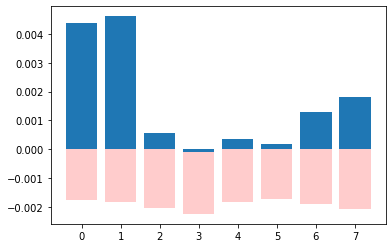

In [16]:
plt.bar(range(len(bert_mean)), bert_mean, color = 'red', alpha = 0.2)
plt.bar(range(len(use_mean)), use_mean)
plt.show()

### High Standard Deviation For Bert Embeddings (RED) Compared with USE Embeddings (BLUE)

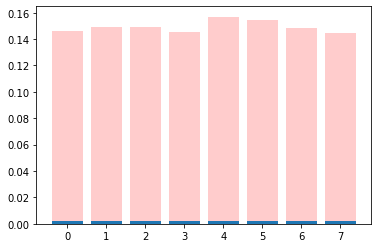

In [34]:
plt.bar(range(len(bert_var)), bert_var, color = 'red', alpha = 0.2)
plt.bar(range(len(use_var)), use_var)
plt.show()

## Visualizing Time To Load Models And Get Embeddings

Text(0.5, 1.0, 'Time To Load Model And Get Embeddings')

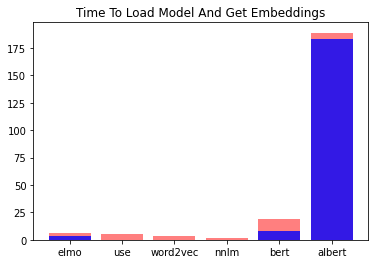

In [38]:
loading_prediction_time = [ 6.225146045999992, 5.199321649000012, 3.3819721850000093, 1.2342575760000045, 18.736032590000008, 188.95563031000003]
prediction_time = [3.245082924000002, 0.011411426999984542, 0.001750579000002972, 0.0014799200000084056, 8.321629771000005, 183.44868148700002]

loading_prediction_lables = ['elmo', 'use', 'word2vec', 'nnlm', 'bert', 'albert']
fig, ax = plt.subplots()
plt.bar(range(len(loading_prediction_time)), loading_prediction_time, color = 'red', alpha = 0.5)
plt.bar(range(len(prediction_time)), prediction_time, color = 'blue', alpha = 0.8)

ax.set_xticklabels(loading_prediction_lables)
ax.set_xticks(np.arange(len(loading_prediction_lables)))
plt.title('Time To Load Model And Get Embeddings')